# QuSpin dynamic export — what is in it, and what it can tell us

The file is `data/QuSpin/dynamic_csv/T2M0-00QK_Data7_flat_interpolation_Quspin_Dynamic.csv`.

A **different flight** from the one in `quspin.ipynb`, and a different kind of
file. That one was raw serial text we parsed ourselves. This one has already
been through somebody else's pipeline: proper CSV, columns named, clocks
reconciled, GPS resampled. Two things follow from that — it is much easier to
load, and we did not do the processing, so some of it has to be checked rather
than trusted.

What is new here is a **calibrated vector channel**. The raw log's 3-axis
magnetometer read 37 uT against a 53 uT scalar and was useless as a
measurement. This one agrees with the scalar to under 1%, which makes
orientation work possible for the first time.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

CSV = (pathlib.Path.cwd().parent / 'data' / 'QuSpin' / 'dynamic_csv'
       / 'T2M0-00QK_Data7_flat_interpolation_Quspin_Dynamic.csv')
FS = 250.0   # Hz, confirmed below

print(CSV.name)
print(f'{CSV.stat().st_size / 1e6:.0f} MB')

T2M0-00QK_Data7_flat_interpolation_Quspin_Dynamic.csv
126 MB


## 1. What we were given

27 columns, no documentation. They fall into five groups.

In [2]:
df = pd.read_csv(CSV)
print(df.shape[0], 'rows x', df.shape[1], 'columns')
print()
for c in df.columns:
    print(f'  {c:<28} {str(df[c].dtype):<8} e.g. {df[c].iloc[0]}')

468600 rows x 27 columns

  Time (ms) [Main]             float64  e.g. 136312.0
  Logger_Time (us) Original    int64    e.g. 41720265
  Logger_Time (us) Mapped      float64  e.g. 41720688.982760906
  GPS_UTC                      str      e.g. 2026-03-14 18:51:40.000
  Mag Data[nT]                 float64  e.g. 53130.097
  Good S - Data                bool     e.g. True
  Data Counter                 float64  e.g. nan
  Sensitivity                  float64  e.g. 90.0
  X                            float64  e.g. -1397.354
  Y                            float64  e.g. -50626.564
  Z                            float64  e.g. 17252.611
  Good V - Data                bool     e.g. True
  Vector Sensitivity           float64  e.g. 61.0
  Latitude                     float64  e.g. 44.076528
  Longitude                    float64  e.g. -79.8099392
  Height                       float64  e.g. 231.4
  UtcDate                      str      e.g. 2026-03-14
  AccelerometerX               float64  e.g.

| group | columns | note |
|---|---|---|
| time | `Time (ms) [Main]`, `Logger_Time (us) Original`, `Logger_Time (us) Mapped`, `GPS_UTC`, `UtcDate` | three clocks and a mapping between two of them |
| scalar | `Mag Data[nT]`, `Good S - Data`, `Sensitivity`, `Data Counter` | the actual measurement |
| vector | `X`, `Y`, `Z`, `Good V - Data`, `Vector Sensitivity` | nT, sensor frame — **new** |
| position | `Latitude`, `Longitude`, `Height` | Height is above the WGS84 ellipsoid |
| IMU | `Accelerometer*`, `Gyro*`, `IMU_VMag*`, `IMU_Temp` | mg, deg/s, uT, degC |

`Data Counter` is empty for every row, and both quality flags are `True`
throughout — no samples were marked bad.

In [3]:
print('Data Counter non-null:', df['Data Counter'].notna().sum())
print('Good S - Data:', df['Good S - Data'].value_counts().to_dict())
print('Good V - Data:', df['Good V - Data'].value_counts().to_dict())
print('any NaN elsewhere:', df.drop(columns=['Data Counter']).isna().sum().sum())

Data Counter non-null: 0
Good S - Data: {True: 468600}
Good V - Data: {True: 468600}
any NaN elsewhere: 0


## 2. The timebase

`Logger_Time (us) Original` is the clock to use — it is the sensor's own, in
microseconds. Dividing the sample count by its span confirms 250 Hz, the same
rate as the raw log.

In [4]:
t = df['Logger_Time (us) Original'].to_numpy() / 1e6
t = t - t[0]
span = t[-1]

print(f'span      {span:.1f} s  =  {span/60:.1f} min')
print(f'rate      {len(t)/span:.2f} Hz')
print(f'UTC       {df.GPS_UTC.iloc[0]}  ->  {df.GPS_UTC.iloc[-1]}')
print(f'site      {df.Latitude.mean():.4f} N, {abs(df.Longitude.mean()):.4f} W')
print()
print('gaps in the clock:')
d = np.diff(t)
print(f'  nominal {1/FS*1e3:.2f} ms, actual median {np.median(d)*1e3:.3f} ms, max {d.max()*1e3:.1f} ms')

span      1874.4 s  =  31.2 min
rate      250.00 Hz
UTC       2026-03-14 18:51:40.000  ->  2026-03-14 19:22:54.000
site      44.0767 N, 79.8122 W

gaps in the clock:
  nominal 4.00 ms, actual median 4.000 ms, max 4.1 ms


31 minutes on 14 March 2026, at 44.08 N 79.81 W — King Township, Ontario.
The same site as the raw log, three months earlier. The clock is even, with no
dropouts worth worrying about.

### What "flat_interpolation" in the filename means

The raw log's GPS arrived once a second. Here it is on every row. That is
interpolation, not better GPS — worth knowing before trusting a position.

In [5]:
# A true 1 Hz fix stream over 31 min would give about 1875 distinct positions.
print('distinct latitudes:', df.Latitude.nunique(), 'in', len(df), 'rows')
print('expected if fixes were left at 1 Hz:', int(span))
print()
print(f'height {df.Height.min():.1f} to {df.Height.max():.1f} m above the WGS84 ellipsoid')
print(f'       ({df.Height.max() - df.Height.min():.1f} m of range)')

distinct latitudes: 306140 in 468600 rows
expected if fixes were left at 1 Hz: 1874

height 228.1 to 277.0 m above the WGS84 ellipsoid
       (48.9 m of range)


## 3. The vector channel

This is the reason to care about this file. `X`, `Y`, `Z` are in nT in the
sensor frame, and their magnitude should equal the scalar reading if the vector
is calibrated. Checking that is the first thing to do.

In [6]:
scalar = df['Mag Data[nT]'].to_numpy()
X, Y, Z = df.X.to_numpy(), df.Y.to_numpy(), df.Z.to_numpy()
V = np.sqrt(X**2 + Y**2 + Z**2)
resid = V - scalar

print(f'scalar    {scalar.mean():9.1f} nT   (range {np.ptp(scalar):.1f})')
print(f'|vector|  {V.mean():9.1f} nT   (range {np.ptp(V):.1f})')
print()
print(f'|vector| - scalar:  mean {resid.mean():+.1f} nT, std {resid.std():.1f},'
      f' range {resid.min():+.0f} to {resid.max():+.0f}')
print(f'as a fraction of the field: {resid.mean()/scalar.mean()*100:.2f}% bias,'
      f' {resid.std()/scalar.mean()*100:.2f}% scatter')

scalar      53159.7 nT   (range 78.9)
|vector|    53560.6 nT   (range 884.3)

|vector| - scalar:  mean +400.9 nT, std 111.1, range -174 to +720
as a fraction of the field: 0.75% bias, 0.21% scatter


A 0.75% bias with 0.2% scatter. Compare the raw log, where the auxiliary
magnetometer read 37 uT against a 53 uT scalar — 30% out. This vector channel
is a real measurement.

It is **not** good to scalar accuracy though, and it must not be used as one.
The scalar varies by only 79 nT across the whole flight; the vector magnitude
wanders by 884 nT. Use the vector for *direction* and the scalar for
*magnitude*.

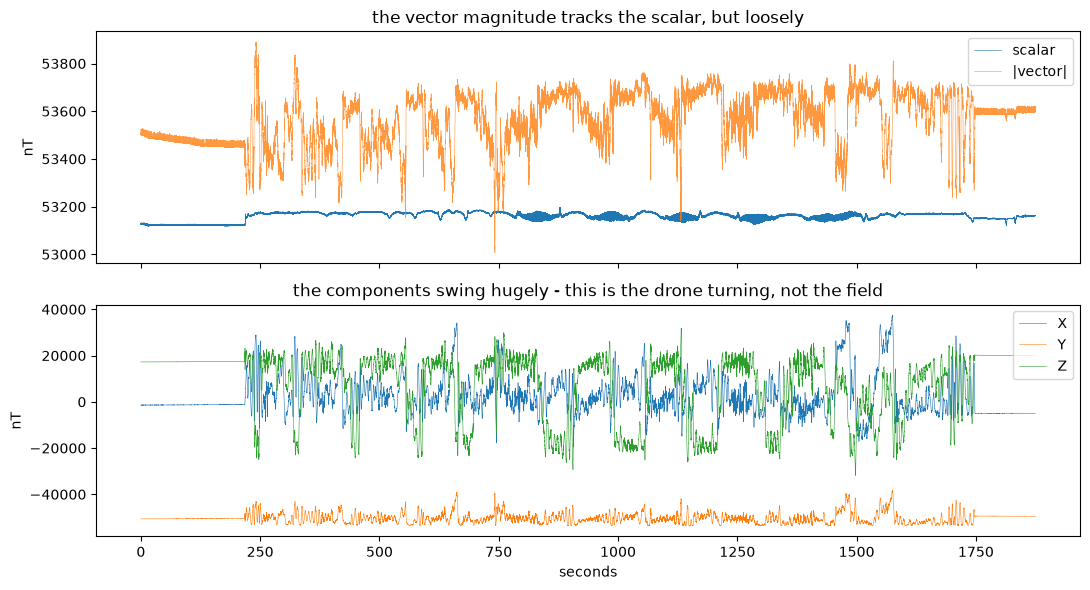

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax[0].plot(t, scalar, lw=0.4, label='scalar')
ax[0].plot(t, V, lw=0.4, alpha=0.8, label='|vector|')
ax[0].set_ylabel('nT')
ax[0].legend(loc='upper right')
ax[0].set_title('the vector magnitude tracks the scalar, but loosely')

for c, nm in ((X, 'X'), (Y, 'Y'), (Z, 'Z')):
    ax[1].plot(t, c, lw=0.4, label=nm)
ax[1].set_ylabel('nT')
ax[1].set_xlabel('seconds')
ax[1].legend(loc='upper right')
ax[1].set_title('the components swing hugely - this is the drone turning, not the field')

plt.tight_layout()

## 4. The noise, and the one line that dominates it

Same question as the raw log: how much noise, and at what frequency. The answer
is the same, and it is stark.

In [8]:
f, P = signal.welch(scalar - scalar.mean(), fs=FS, nperseg=8192)
asd = np.sqrt(P) * 1000   # pT / sqrt(Hz)

for lo, hi, label in [(0.0, 0.1, '< 0.1 Hz  (real geology)'),
                      (1, 10, '1 - 10 Hz'),
                      (20, 50, '20 - 50 Hz'),
                      (55, 65, '55 - 65 Hz  (mains)'),
                      (100, 125, '100 - 125 Hz  (noise floor)')]:
    m = (f >= lo) & (f < hi)
    print(f'  {label:<28} median {np.median(asd[m]):8.1f}   peak {asd[m].max():9.1f}  pT/rtHz')

print()
print('strongest lines (Hz):', np.round(np.sort(f[np.argsort(P)[-6:]]), 2))

  < 0.1 Hz  (real geology)     median   9394.6   peak   17690.2  pT/rtHz
  1 - 10 Hz                    median     13.2   peak     235.0  pT/rtHz
  20 - 50 Hz                   median      8.1   peak     561.2  pT/rtHz
  55 - 65 Hz  (mains)          median     16.8   peak   15868.4  pT/rtHz
  100 - 125 Hz  (noise floor)  median      4.0   peak      30.1  pT/rtHz

strongest lines (Hz): [3.000e-02 6.000e-02 9.000e-02 5.997e+01 6.000e+01 6.003e+01]


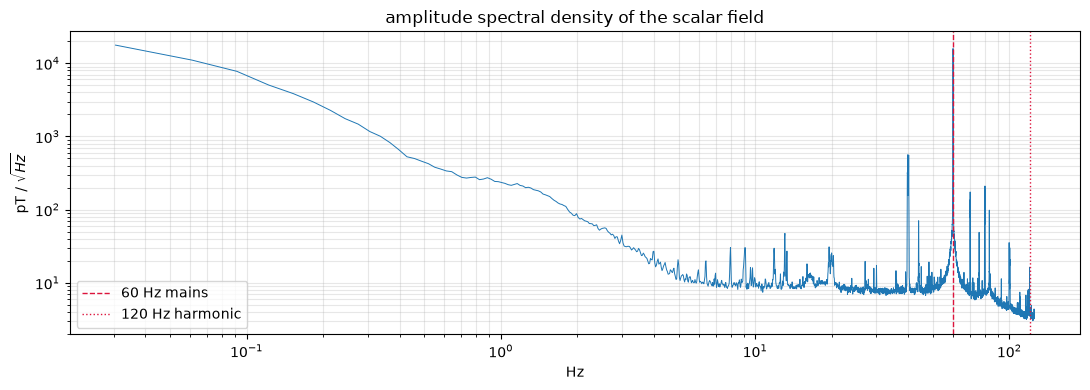

In [9]:
plt.figure(figsize=(11, 4))
plt.loglog(f[1:], asd[1:], lw=0.7)
plt.axvline(60, color='crimson', ls='--', lw=1, label='60 Hz mains')
plt.axvline(120, color='crimson', ls=':', lw=1, label='120 Hz harmonic')
plt.xlabel('Hz')
plt.ylabel('pT / $\\sqrt{Hz}$')
plt.title('amplitude spectral density of the scalar field')
plt.legend()
plt.grid(alpha=0.3, which='both')
plt.tight_layout()

Two things to take from this:

- The **noise floor is about 4 pT/rtHz** at 100-125 Hz, where nothing real
  lives. That is the instrument, and it is excellent.
- **60.00 Hz is 15,900 pT/rtHz** — four thousand times the floor. North
  American mains, picked up from power lines near the field, exactly as in the
  June flight.

The low-frequency end is large (9,400 pT/rtHz) but that is the signal: the
drone flying over changing geology.

> Ireland runs at **50 Hz**, not 60. Any filter written against this dataset
> must have the mains frequency as a parameter, not a constant, or it will
> silently pass the interference on Irish data.

## 5. Does motion add noise? The trap in this question

A scalar magnetometer on a rotating platform could plausibly read worse while
turning. Binning the high-passed field by rotation rate seems to say it does —
noise climbing from 3.4 to 5.3 nT.

In [10]:
gyro = np.sqrt(df.GyroX**2 + df.GyroY**2 + df.GyroZ**2).to_numpy()

hp = lambda x: signal.filtfilt(*signal.butter(2, 0.1/(FS/2), 'high'), x)
raw_hf = hp(scalar)

def by_rotation(sig, label):
    q = np.quantile(gyro, [0, .25, .5, .75, .9, 1.0])
    print(label)
    for i in range(len(q) - 1):
        m = (gyro >= q[i]) & (gyro < q[i + 1])
        print(f'   {q[i]:6.1f} - {q[i+1]:6.1f} deg/s | n={m.sum():7d} | std {sig[m].std():6.3f} nT')

by_rotation(raw_hf, 'high-passed above 0.1 Hz, as recorded:')

high-passed above 0.1 Hz, as recorded:
      0.1 -    5.1 deg/s | n= 117149 | std  3.394 nT
      5.1 -   11.1 deg/s | n= 117150 | std  5.035 nT
     11.1 -   18.5 deg/s | n= 117149 | std  5.239 nT
     18.5 -   29.8 deg/s | n=  70289 | std  5.271 nT
     29.8 -  112.1 deg/s | n=  46858 | std  4.825 nT


It does not. That trend is the 60 Hz line, not the motion.

The flight is a lawnmower pattern. The drone rotates at the turns — which are
at the edges of the field, nearer the power lines. Rotation and interference
are correlated through the *geometry of the survey*, not through the physics of
the sensor.

Notch the mains out and re-ask the question.

In [11]:
notched = scalar.copy()
for f0 in (60, 120):
    notched = signal.filtfilt(*signal.iirnotch(f0, 30, FS), notched)

print(f'std above 0.1 Hz, as recorded : {raw_hf.std():.3f} nT')
print(f'std above 0.1 Hz, mains notched: {hp(notched).std():.3f} nT')
print(f'  -> the 60 Hz line is {(1 - hp(notched).var()/raw_hf.var())*100:.0f}% of the noise power')
print()

band = signal.filtfilt(*signal.butter(2, [0.1/(FS/2), 30/(FS/2)], 'band'), notched)
by_rotation(band, 'mains notched, 0.1 - 30 Hz motion band:')

print()
print(f'correlation |gyro| vs |field|       : {np.corrcoef(gyro, np.abs(band))[0,1]:+.3f}')
acc = np.sqrt(df.AccelerometerX**2 + df.AccelerometerY**2 + df.AccelerometerZ**2).to_numpy()
print(f'correlation |accel - 1g| vs |field| : {np.corrcoef(np.abs(acc-1000), np.abs(band))[0,1]:+.3f}')

std above 0.1 Hz, as recorded : 4.752 nT
std above 0.1 Hz, mains notched: 1.353 nT
  -> the 60 Hz line is 92% of the noise power

mains notched, 0.1 - 30 Hz motion band:
      0.1 -    5.1 deg/s | n= 117149 | std  1.474 nT
      5.1 -   11.1 deg/s | n= 117150 | std  1.161 nT
     11.1 -   18.5 deg/s | n= 117149 | std  1.234 nT
     18.5 -   29.8 deg/s | n=  70289 | std  1.505 nT
     29.8 -  112.1 deg/s | n=  46858 | std  1.211 nT

correlation |gyro| vs |field|       : +0.101
correlation |accel - 1g| vs |field| : +0.085


**No motion sensitivity.** Flat across every rotation-rate band, correlation
+0.10 against rotation and +0.09 against vibration. Once the mains line is
removed the sensor reads 1.35 nT RMS regardless of what the drone is doing.

This is a useful result for the error model: it says a single noise figure is
enough, with no manoeuvre-dependent term.

## 6. Attitude coverage — and why dead zones stay unknown

The vector channel gives the field direction in the sensor frame, so the angle
between the field and each sensor axis is a straight calculation. That angle is
what drives heading error and dead zones in a scalar OPM, so this is the
measurement we would need to model them.

In [12]:
theta = {nm: np.degrees(np.arccos(np.clip(c / V, -1, 1)))
         for nm, c in (('X', X), ('Y', Y), ('Z', Z))}

print('angle between the field and each sensor axis:')
for nm, th in theta.items():
    print(f'  theta_{nm}: {th.min():6.1f} to {th.max():6.1f} deg'
          f'  (mean {th.mean():6.1f}, std {th.std():5.1f}) -> {np.ptp(th):5.1f} deg covered')

angle between the field and each sensor axis:
  theta_X:   45.5 to  111.3 deg  (mean   87.6, std   9.2) ->  65.8 deg covered
  theta_Y:  135.5 to  179.8 deg  (mean  161.0, std   6.7) ->  44.3 deg covered
  theta_Z:   53.4 to  126.4 deg  (mean   81.4, std  15.4) ->  73.0 deg covered


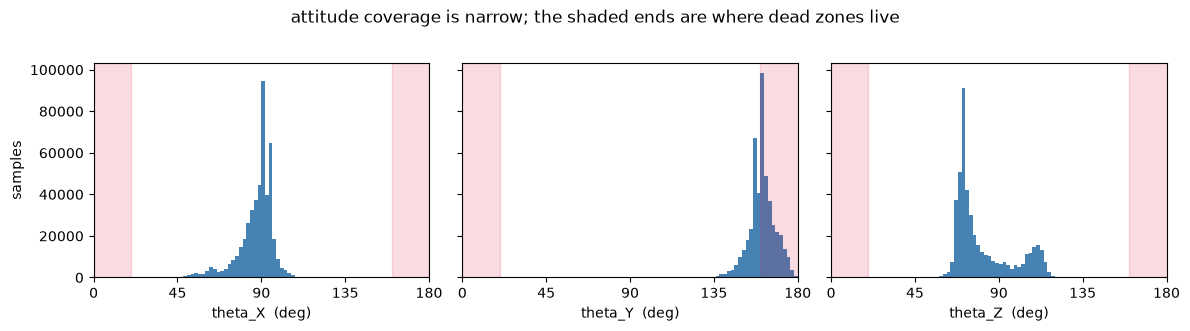

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, (nm, th) in zip(ax, theta.items()):
    a.hist(th, bins=90, range=(0, 180), color='steelblue')
    a.axvspan(0, 20, color='crimson', alpha=0.15)
    a.axvspan(160, 180, color='crimson', alpha=0.15)
    a.set_xlim(0, 180)
    a.set_xlabel(f'theta_{nm}  (deg)')
    a.set_xticks([0, 45, 90, 135, 180])
ax[0].set_ylabel('samples')
fig.suptitle('attitude coverage is narrow; the shaded ends are where dead zones live', y=1.02)
plt.tight_layout()

The flight covers 66 deg on X, 44 deg on Y and 73 deg on Z, all of it clustered
near 90 deg — level flight with the nose swinging round. The ends of the range,
where a scalar OPM loses signal, are never visited.

The sensor's own reported `Sensitivity` confirms there is nothing to fit: it
barely moves across everything flown.

In [14]:
bins = np.arange(50, 131, 10)
idx = np.digitize(theta['Z'], bins)

print(' theta_Z bin |    n    | Sensitivity | Vector Sens')
for b in range(1, len(bins)):
    m = idx == b
    if m.sum() > 200:
        print(f'  {bins[b-1]:3d} - {bins[b]:3d}  | {m.sum():7d} |'
              f'    {df.Sensitivity[m].mean():5.1f}    |    {df["Vector Sensitivity"][m].mean():5.1f}')

print()
print(f'Sensitivity over the whole flight: {df.Sensitivity.min():.0f} to {df.Sensitivity.max():.0f}')

 theta_Z bin |    n    | Sensitivity | Vector Sens
   50 -  60  |    1214 |     85.0    |     53.9
   60 -  70  |   99694 |     87.1    |     55.2
   70 -  80  |  199930 |     87.3    |     55.1
   80 -  90  |   48241 |     86.8    |     53.9
   90 - 100  |   30027 |     87.1    |     54.2
  100 - 110  |   48984 |     85.3    |     53.6
  110 - 120  |   39921 |     83.8    |     53.1
  120 - 130  |     589 |     84.1    |     53.1

Sensitivity over the whole flight: 80 to 97


A spread of about 3 counts out of 80-97, with no trend against angle. So this
file cannot characterise the orientation response — not because the sensor is
well behaved, but because the flight never put it in an awkward attitude.

Closing that gap needs a **deliberate ground rotation test**: the sensor on a
non-magnetic gimbal, swept through full yaw at several pitch angles, logging
scalar, vector and `Sensitivity` together.

## 7. The flight

extent      793 x 328 m
field range 78.9 nT


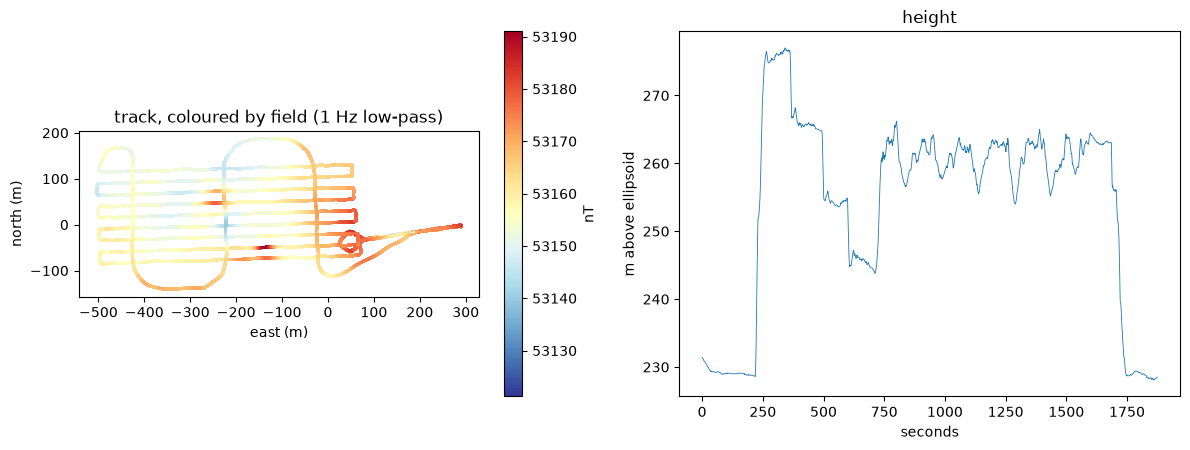

In [15]:
# Local metres about the mean position, so the plot is in sensible units.
lat0, lon0 = df.Latitude.mean(), df.Longitude.mean()
mx = np.radians(df.Longitude - lon0) * 6_371_000 * np.cos(np.radians(lat0))
my = np.radians(df.Latitude - lat0) * 6_371_000

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

s = ax[0].scatter(mx, my, c=signal.filtfilt(*signal.butter(2, 1/(FS/2), 'low'), scalar),
                  s=1, cmap='RdYlBu_r')
ax[0].set_aspect('equal')
ax[0].set_xlabel('east (m)')
ax[0].set_ylabel('north (m)')
ax[0].set_title('track, coloured by field (1 Hz low-pass)')
plt.colorbar(s, ax=ax[0], label='nT')

ax[1].plot(t, df.Height, lw=0.6)
ax[1].set_xlabel('seconds')
ax[1].set_ylabel('m above ellipsoid')
ax[1].set_title('height')

print(f'extent      {np.ptp(mx):.0f} x {np.ptp(my):.0f} m')
print(f'field range {np.ptp(scalar):.1f} nT')
plt.tight_layout()

## 8. What this file is good for

| | |
|---|---|
| noise floor | **4 pT/rtHz** broadband |
| in-band noise, mains removed | **1.35 nT RMS** above 0.1 Hz |
| mains interference | **15.9 nT/rtHz at 60 Hz** — 92% of the noise power |
| motion sensitivity | **none detectable** |
| vector calibration | 0.75% bias, 0.2% scatter against the scalar |
| orientation response | **not measurable from this flight** |

Good enough to parameterise a sensor error model: one noise figure, one mains
line, no manoeuvre term. Not good enough for an orientation model, which needs
a rotation test on the ground.

Two things this notebook does not do. It takes the upstream processing on
trust, in particular whatever produced `Logger_Time (us) Mapped` from
`Original` — somebody solved a clock alignment problem there and the method is
not recorded. And it keeps all its loading code here rather than in
`src/quspin/`, because this is a one-off export in a format the parser does not
handle; if more files arrive like this, that is the point to promote it to a
module.